# Taller 4: Lógica difusa robot
**Estudiante:** Juan Felipe Rodríguez Galindo - 20261595004

Inteligencia Computacional




In [1]:
import itertools, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
SEMILLA = 42
PRUEBA = 0.3
RUTA = "bibliografia/"
SENSORES = ["frontal","izquierda","derecha","atras"]
CLASES = ["Move-Forward", "Sharp-Right-Turn", "Slight-Left-Turn", "Slight-Right-Turn"]
os.makedirs("figuras", exist_ok=True)

In [3]:
d4 = pd.read_csv(RUTA+"sensor_readings_4.csv", header=None, names=SENSORES + ["clase"])
d2 = pd.read_csv(RUTA+"sensor_readings_2.csv", header=None, names=["frontal", "izquierda", "clase"])

print(d4.shape, d2.shape)

print("Mismas lecturas frontal e izquierda",(d4[["frontal", "izquierda", "clase"]].values == d2.values).all())
print(d4["clase"].value_counts())

d4.describe().round(2)

(5456, 5) (5456, 3)
Mismas lecturas frontal e izquierda True
clase
Move-Forward         2205
Sharp-Right-Turn     2097
Slight-Right-Turn     826
Slight-Left-Turn      328
Name: count, dtype: int64


,frontal,izquierda,derecha,atras
count,5456.00,5456.00,5456.00,5456.00
mean,1.29,0.68,1.88,1.27
std,0.63,0.34,0.56,0.82
min,0.50,0.34,0.84,0.37
25%,0.83,0.50,1.47,0.79
50%,1.09,0.61,1.75,1.07
75%,1.52,0.75,2.14,1.40
max,5.00,5.00,5.00,5.00


In [4]:
y = d4["clase"].map(CLASES.index).values
idx_tr, idx_te = train_test_split(np.arange(len(d4)), test_size=PRUEBA, stratify=y, random_state=SEMILLA)
entreno = d4.iloc[idx_tr]
print("Entrenamiento", len(idx_tr), "| pruebas", len(idx_te))

Entrenamiento 3819 | pruebas 1637


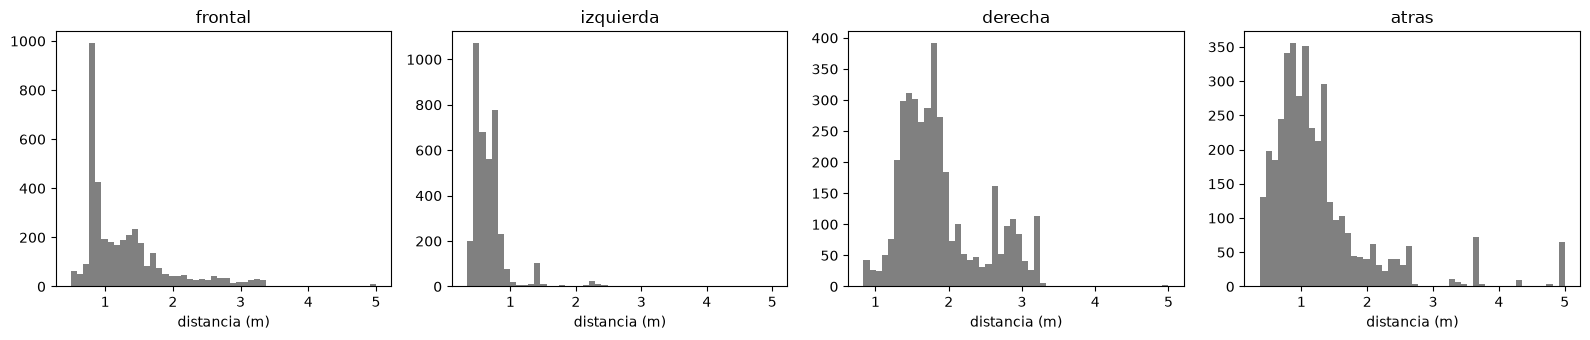

In [5]:
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.5))

for eje, s in zip(ejes, SENSORES):
    eje.hist(entreno[s], bins=50, color="gray")
    eje.set(title=s, xlabel="distancia (m)")
plt.tight_layout()
plt.savefig("figuras/histogramas.png", dpi=150)
plt.show()

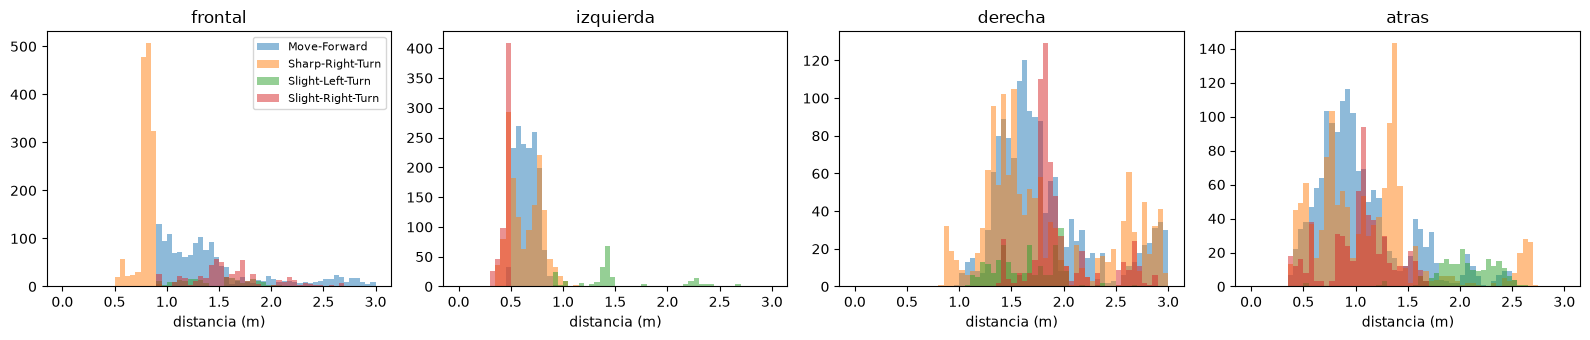

frontal             izquierda              derecha         \
                      min median  max       min median   max     min median   
clase                                                                         
Move-Forward          0.9   1.34  5.0      0.50   0.65  0.90    0.97   1.70   
Sharp-Right-Turn      0.5   0.81  0.9      0.35   0.62  5.00    0.84   1.69   
Slight-Left-Turn      0.9   1.56  2.1      0.90   1.41  5.00    1.09   1.66   
Slight-Right-Turn     0.9   1.57  5.0      0.34   0.47  0.49    1.39   1.84   

                        atras               
                    max   min median   max  
clase                                       
Move-Forward       5.00  0.37   0.94  5.00  
Sharp-Right-Turn   5.00  0.37   1.17  5.00  
Slight-Left-Turn   2.68  0.52   2.06  3.54  
Slight-Right-Turn  5.00  0.37   1.07  1.69

In [6]:
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.5))

for eje, s in zip(ejes, SENSORES):
    for c in CLASES:
        eje.hist(entreno.loc[entreno["clase"] == c, s], bins=np.linspace(0,3,61), alpha=0.5, label=c)
    eje.set(title=s, xlabel="distancia (m)")

ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figuras/histogramas_clase.png", dpi=150)
plt.show()
entreno.groupby("clase")[SENSORES].agg(["min","median","max"]).round(2)

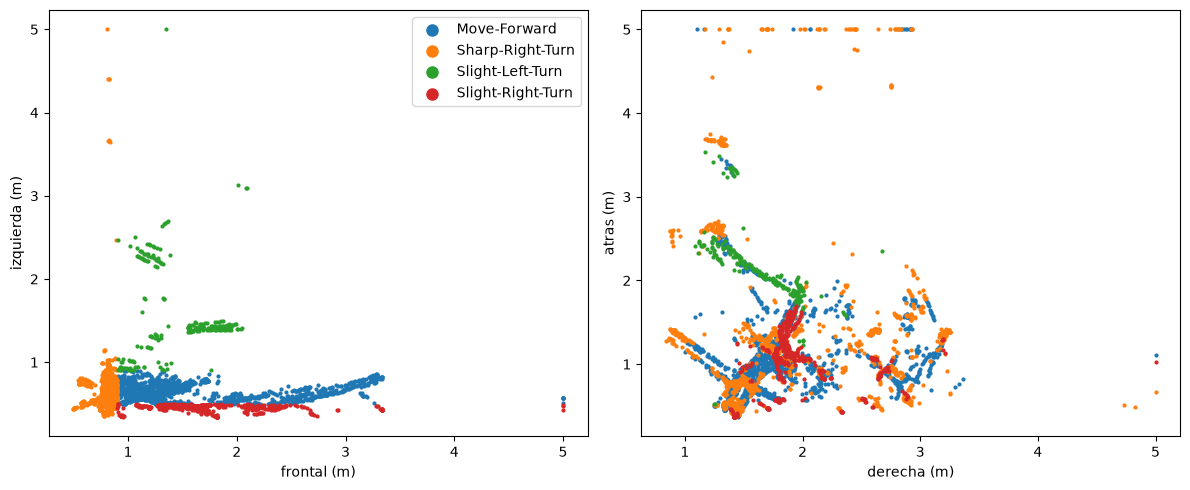

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

for c in CLASES:
    m = entreno["clase"] == c
    ejes[0].scatter(entreno.loc[m, "frontal"], entreno.loc[m, "izquierda"], s=4, label=c)
    ejes[1].scatter(entreno.loc[m, "derecha"], entreno.loc[m, "atras"], s=4, label=c)
ejes[0].set(xlabel="frontal (m)", ylabel="izquierda (m)")
ejes[1].set(xlabel="derecha (m)", ylabel="atras (m)")
ejes[0].legend(markerscale=4)
plt.tight_layout()
plt.savefig("figuras/nube_puntos.png", dpi=150)
plt.show()

In [8]:
entreno[["derecha","atras"]].quantile([1/3, 2/3]).round(2)

,derecha,atras
0.333333,1.57,0.87
0.666667,1.92,1.30


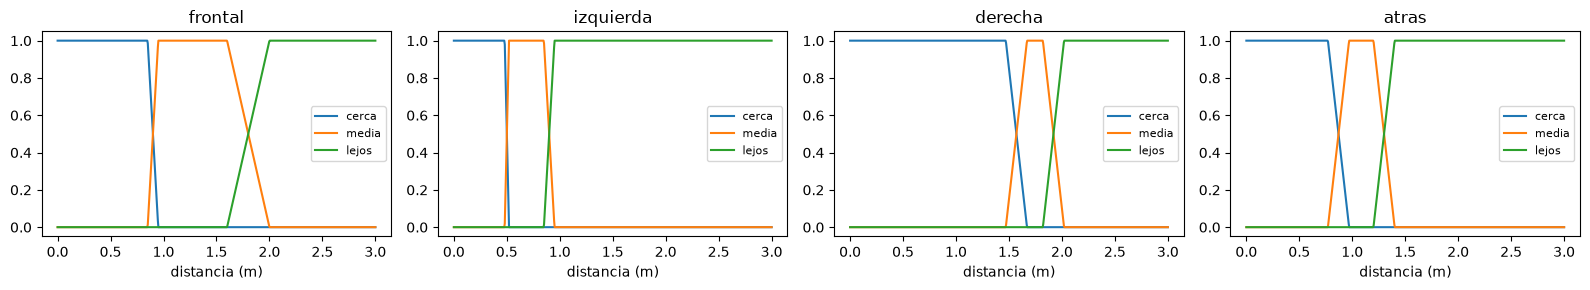

In [9]:
def trampf(x, a, b, c, d):
    x=np.asarray(x, dtype=float)
    sube = np.ones_like(x) if b == a else (x-a) / (b-a)
    baja = np.ones_like(x) if d == c else (d-x) / (d-c)
    return np.clip(np.minimum(np.minimum(sube, 1), baja),0,1)
# frontal era 0.9 iz 0.5 y 0.9, derecha atras terciles
MF = {
    "frontal" : {
        "cerca" : (0, 0, 0.85, 0.95),
        "media" : (0.85, 0.95, 1.6, 2.0),
        "lejos" : (1.6, 2.0, 5, 5),
    },
    "izquierda" : {
        "cerca" : (0, 0, 0.48, 0.52),
        "media" : (0.48, 0.52, 0.85, 0.95),
        "lejos" : (0.85, 0.95, 5, 5),
    },
    "derecha" : {
        "cerca" : (0, 0, 1.47, 1.67),
        "media" : (1.47, 1.67, 1.82, 2.02),
        "lejos" : (1.82, 2.02, 5, 5),
    },
    "atras" : {
        "cerca" : (0, 0, 0.77, 0.97),
        "media" : (0.77, 0.97, 1.2, 1.4),
        "lejos" : (1.2, 1.4, 5, 5),
    },
}

x=np.linspace(0,3,600)
fig, ejes = plt.subplots(1,4, figsize=(16,3))
for eje, s in zip(ejes, SENSORES):
    for etiqueta, p in MF[s].items():
        eje.plot(x, trampf(x, *p), label=etiqueta)
    eje.set(title=s, xlabel="distancia (m)")
    eje.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figuras/funciones_pertenencia.png", dpi=150)
plt.show()

In [10]:
def grados(X,sensores):
    return [np.stack([trampf(X[:,j], *p) for p in MF[s].values()], axis=1,) for j,s in enumerate(sensores)]

def fuerza(G, antecedentes):
    f = np.ones((len(G[0]), len(antecedentes)))
    for k, ant in enumerate(antecedentes):
        for j, e in enumerate(ant):
            f[:, k] *= G[j][:,e]
    return f

def entrenar(X, y, sensores):
    antecedentes = list(itertools.product(*[range(len(MF[s])) for s in sensores]))
    f = fuerza(grados(X, sensores), antecedentes)
    peso = np.stack([f[y==k].sum(axis=0) for k in range(len(CLASES))], axis=1)
    return antecedentes, peso.argmax(axis=1), peso

def predecir(X, sensores, antecedentes, consecuente):
    f = fuerza(grados(X, sensores), antecedentes)
    return consecuente[f.argmax(axis=1)]

def reglas_en_palabras(sensores, antecedentes, consecuente, peso):
    for ant, c, w in zip(antecedentes, consecuente, peso):
        if w.sum() > 0:
            con = " Y ".join(f"{s} es {list(MF[s])[e]}" for s,e in zip(sensores, ant))
            print(f"SI {con} ENTONCES {CLASES[c]} (soporte {w.sum():.0f})")



SI frontal es cerca Y izquierda es cerca ENTONCES Sharp-Right-Turn (soporte 380)
SI frontal es cerca Y izquierda es media ENTONCES Sharp-Right-Turn (soporte 975)
SI frontal es cerca Y izquierda es lejos ENTONCES Sharp-Right-Turn (soporte 77)
SI frontal es media Y izquierda es cerca ENTONCES Slight-Right-Turn (soporte 441)
SI frontal es media Y izquierda es media ENTONCES Move-Forward (soporte 1155)
SI frontal es media Y izquierda es lejos ENTONCES Slight-Left-Turn (soporte 180)
SI frontal es lejos Y izquierda es cerca ENTONCES Slight-Right-Turn (soporte 179)
SI frontal es lejos Y izquierda es media ENTONCES Move-Forward (soporte 384)
SI frontal es lejos Y izquierda es lejos ENTONCES Slight-Left-Turn (soporte 48)
Reglas : 9 | exactitud de prueba : 0.99


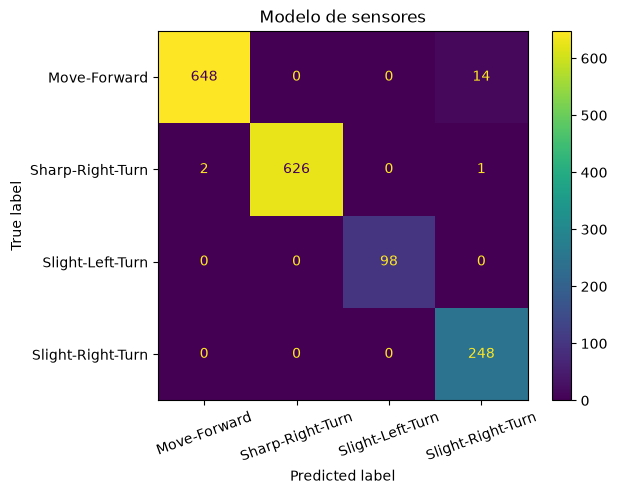

In [11]:
S2 = ["frontal","izquierda"]
X2 = d2[S2].values
ant2, cons2, peso2 = entrenar(X2[idx_tr], y[idx_tr], S2)

reglas_en_palabras(S2, ant2, cons2, peso2)

pred2 = predecir(X2[idx_te], S2, ant2, cons2)
print(f"Reglas : {len(ant2)} | exactitud de prueba : {round(accuracy_score(y[idx_te], pred2),2)}")

ConfusionMatrixDisplay(confusion_matrix(y[idx_te], pred2), display_labels=CLASES).plot(xticks_rotation=20)
plt.title("Modelo de sensores")
plt.savefig("figuras/confusion_2.png")
plt.show()


Reglas : 81 | sin datos de entrenamiento : 8
Reglas por clase : {'Move-Forward': 18, 'Sharp-Right-Turn': 30, 'Slight-Left-Turn': 12, 'Slight-Right-Turn': 13}
Exactitud de prueba : 0.989


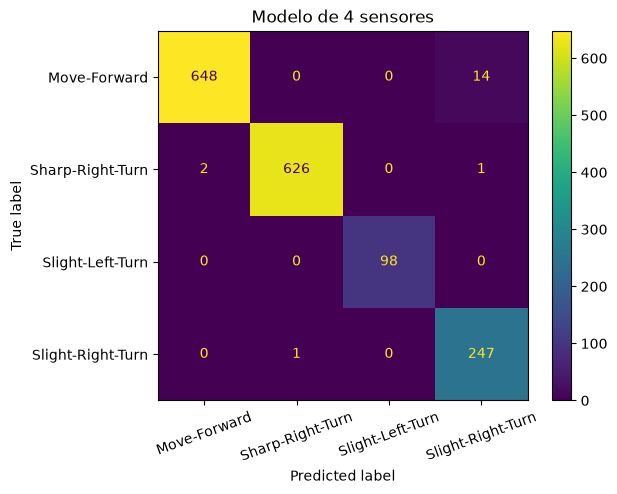

In [12]:
X4 = d4[SENSORES].values
ant4, cons4, peso4 = entrenar(X4[idx_tr], y[idx_tr], SENSORES)
sindatos = int((peso4.sum(axis=1) == 0).sum())
print(f"Reglas : {len(ant4)} | sin datos de entrenamiento : {sindatos}")
print(f"Reglas por clase : { {CLASES[k]: int((cons4[peso4.sum(axis=1) > 0] == k).sum()) for k in range(len(CLASES))} }")
pred4 = predecir(X4[idx_te], SENSORES, ant4, cons4)
print(f"Exactitud de prueba : {round(accuracy_score(y[idx_te], pred4),4)}")

ConfusionMatrixDisplay(confusion_matrix(y[idx_te], pred4), display_labels=CLASES).plot(xticks_rotation=20)
plt.title("Modelo de 4 sensores")
plt.savefig("figuras/confusion_4.png")
plt.show()


In [13]:
resumen = pd.DataFrame({
    "sensores": [2, 4],
    "reglas": [len(ant2), len(ant4)],
    "exactitud": [
        round(accuracy_score(y[idx_te], pred2), 2),
        round(accuracy_score(y[idx_te], pred4), 4)
    ],
    "errores": [
        int((pred2 != y[idx_te]).sum()),
        int((pred4 != y[idx_te]).sum())
    ],
})

print(resumen.round(4).to_string(index=False))
print("Predicciones distintas entre los dos modelos:", int((pred2 != pred4).sum()))

 sensores  reglas  exactitud  errores
        2       9      0.990       17
        4      81      0.989       18
Predicciones distintas entre los dos modelos: 1
